In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import machine_learning_models as mlm
pd.set_option('display.max_rows', 100)

In [2]:
df = pd.read_csv(r'C:\Users\mechz\Documents\Jobs_Analysis\job_postings.csv')
X = df.drop(columns=['salary_year_avg'])
predictors = X.columns.to_list()
numerical_columns = ['job_posted_year', 'job_posted_month_sine']
numerical_indices = X.columns.get_indexer(numerical_columns)
X = X.to_numpy()
y = df['salary_year_avg'].to_numpy()

training_index, testing_index = mlm.train_test_split(X.shape[0], 10000)
X_training = X[training_index]
y_training = y[training_index]
X_testing = X[testing_index]
y_testing = y[testing_index]
y_training_scaled = (y_training - np.mean(y_training)) / np.std(y_training)
y_testing_scaled = (y_testing - np.mean(y_training)) / np.std(y_training)

for index in numerical_indices:
    mean = np.mean(X_training[:,index])
    std = np.std(X_training[:, index])
    X_training[:,index] = (X_training[:,index] - mean) / std
    X_testing[:,index] = (X_testing[:,index] - mean) / std

special_groups = [[i for i, name in enumerate(predictors) if name.startswith('job_title_short_')], [i for i, name in enumerate(predictors) if name.startswith('job_country_')], [i for i, name in enumerate(predictors) if name.startswith('job_via_')]]
continuous_predictors = [i for i, name in enumerate(predictors) if name.startswith('job_posted_')]
indices_in_special_groups = [c for g in special_groups for c in g]
groups = special_groups + [[i] for i in range(X.shape[1]) if i not in indices_in_special_groups]
groups = sorted(groups, key=min)

print(f'The mean, median, and standard deviation of the salary are {np.mean(y):.3f}, {np.median(y):.3f}, and {np.std(y):.3f} respectively.')

The mean, median, and standard deviation of the salary are 122390.906, 115000.000, and 47019.486 respectively.


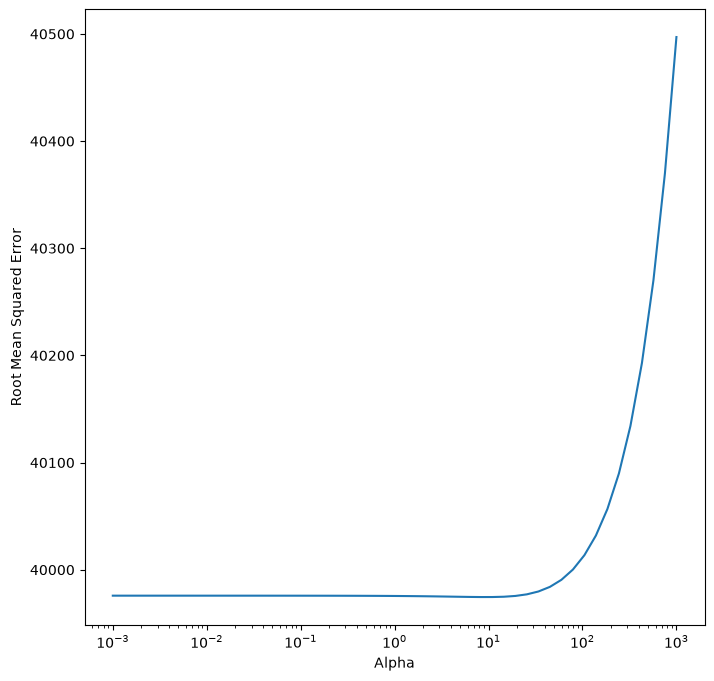

The best alpha value is 8.2864 which gives a testing root mean squared error of 38415.173 and testing R squared score of 0.307.


,parameters,permutation_importance,direction
variables,,,
job_title_short_Senior Data Scientist,21317.831331,6.03,23686.479256
job_title_short_Senior Data Engineer,13304.253369,6.03,14782.503743
job_title_short_Machine Learning Engineer,9000.012821,6.03,10000.014246
job_title_short_Software Engineer,8789.269754,6.03,9765.855282
job_title_short_Data Scientist,5257.220599,6.03,5841.356221
job_title_short_Cloud Engineer,1690.849533,6.03,1878.721703
job_title_short_Data Engineer,-428.814740,6.03,-476.460822
job_title_short_Senior Data Analyst,-9340.427059,6.03,-10378.252288
job_title_short_Business Analyst,-23958.723344,6.03,-26620.803716


In [3]:
alphas = np.logspace(-3, 3, 50)
rmses = {}
for alpha in alphas:
    rmses_one_fold = []
    for fold in mlm.kfold_cross_validation(5, X_training.shape[0]):
        inner_model = mlm.Ridge_Regression(alpha=alpha)
        inner_model.fit(np.delete(X_training, fold, axis=0), np.delete(y_training, fold, axis=0))
        predictions = inner_model.predict(X_training[fold])
        rmse = np.sqrt(np.mean((y_training[fold] - predictions)**2))
        rmses_one_fold.append(rmse)
    average_rmse = np.mean(rmses_one_fold)
    rmses.update({alpha:average_rmse})
best_alpha = min(rmses, key=rmses.get)

fig, ax = plt.subplots(figsize=(8,8))
ax.semilogx(rmses.keys(), rmses.values())
ax.set_xlabel('Alpha')
ax.set_ylabel('Root Mean Squared Error')
plt.show()

model = mlm.Ridge_Regression(alpha=best_alpha)
model.fit(X_training, y_training)
predictions = model.predict(X_testing)
rmse = np.sqrt(np.mean((y_testing - predictions)**2))
r2 = 1 - (np.sum((y_testing - predictions)**2)) / (np.sum((y_testing - np.mean(y_testing))**2))
print(f'The best alpha value is {best_alpha:.4f} which gives a testing root mean squared error of {rmse:.3f} and testing R squared score of {r2:.3f}.')

parameters = predictors
parameters_dictionary = {'variables':parameters, 'parameters':model.parameters.reshape(-1), 'permutation_importance':np.round(model.permutation_importances(X_testing, y_testing, groups) * 100, 2), 'direction':model.marginal_importance(X_testing, y_testing, groups, continuous_predictors)}
parameters_df = pd.DataFrame(parameters_dictionary).sort_values(by=['permutation_importance', 'direction'], ascending=False).set_index('variables', drop=True)
display(parameters_df)

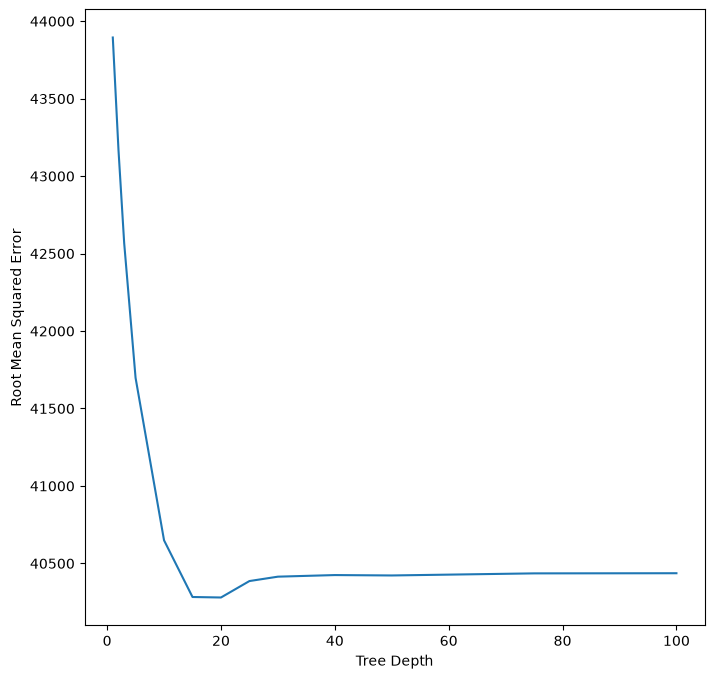

The best tree depth is 20 which gives a testing root mean squared error of 37570.210 and testing R squared score of 0.338.


,permutation_importance,sse_importance,direction
variables,,,
job_title_short_Data Analyst,5.06,33.02,-29110.591209
job_title_short_Business Analyst,5.06,5.45,-33369.535925
job_title_short_Senior Data Analyst,5.06,2.95,-12192.916501
job_title_short_Data Engineer,5.06,1.92,-2725.802702
job_title_short_Senior Data Scientist,5.06,1.04,20651.487497
job_title_short_Software Engineer,5.06,0.92,10048.080575
job_title_short_Data Scientist,5.06,0.77,2398.135994
job_title_short_Senior Data Engineer,5.06,0.70,14218.987606
job_title_short_Machine Learning Engineer,5.06,0.25,19272.967092


In [4]:
depths = [1, 2, 3, 5, 10, 15, 20, 25, 30, 40, 50, 75, 100]
rmses = []
for depth in depths:
    rmses_one_fold = []
    for fold in mlm.kfold_cross_validation(5, len(y_training)):
        inner_model = mlm.Regression_Tree(X.shape[1], max_depth=depth)
        inner_model.fit(np.delete(X_training, fold, axis=0), np.delete(y_training, fold))
        predictions = inner_model.predict(X_training[fold])
        rmse = np.sqrt(np.mean((y_training[fold] - predictions)**2))
        rmses_one_fold.append(rmse)
    rmses.append(np.mean(rmses_one_fold))
lowest_rmse = min(rmses)
best_depth = depths[rmses.index(lowest_rmse)]

fig, ax = plt.subplots(figsize=(8,8))
ax.plot(depths, rmses)
ax.set_xlabel('Tree Depth')
ax.set_ylabel('Root Mean Squared Error')
plt.show()

model = mlm.Regression_Tree(X.shape[1], max_depth=best_depth)
model.fit(X_training, y_training)
predictions = model.predict(X_testing)
rmse = np.sqrt(np.mean((y_testing - predictions)**2))
r2 = 1 - (np.sum((y_testing - predictions)**2)) / (np.sum((y_testing - np.mean(y_testing))**2))
print(f'The best tree depth is {best_depth} which gives a testing root mean squared error of {rmse:.3f} and testing R squared score of {r2:.3f}.')

parameters = predictors
parameters_dictionary = {'variables':parameters, 'permutation_importance':np.round(model.permutation_importances(X_testing, y_testing, groups) * 100, 2), 'sse_importance':np.round(model.feature_importances() * 100, 2), 'direction':model.marginal_importance(X_testing, y_testing, groups, continuous_predictors)}
parameters_df = pd.DataFrame(parameters_dictionary).sort_values(by=['permutation_importance', 'sse_importance'], ascending=False).set_index('variables', drop=True)
display(parameters_df)

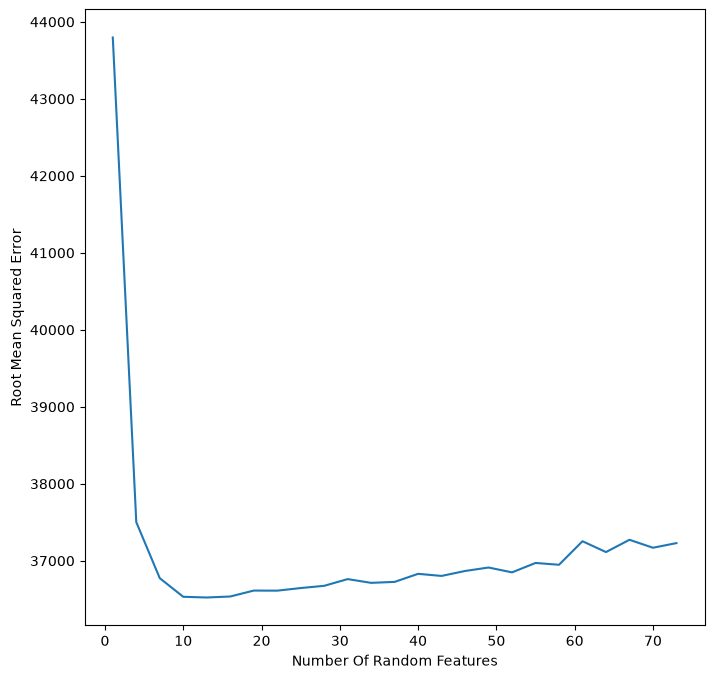

The best number of random features is 13 which gives a testing root mean squared error of 34157.628 and testing R squared score of 0.452.


,permutation_importance,sse_importance,direction
variables,,,
job_title_short_Data Analyst,4.47,12.83,-25991.003028
job_title_short_Senior Data Scientist,4.47,2.88,21398.903341
job_title_short_Data Scientist,4.47,1.92,3883.061592
job_title_short_Business Analyst,4.47,1.61,-17995.239003
job_title_short_Data Engineer,4.47,1.48,-794.688185
job_title_short_Senior Data Engineer,4.47,1.36,11625.359294
job_title_short_Software Engineer,4.47,0.79,1144.597225
job_title_short_Senior Data Analyst,4.47,0.72,-5204.180887
job_title_short_Machine Learning Engineer,4.47,0.70,12351.750425


In [5]:
random_feature_numbers = np.unique(np.linspace(1, X_training.shape[1], 25).astype(np.int32))
rmses = []
for random_feature_number in random_feature_numbers:
    rmses_one_fold = []
    for fold in mlm.kfold_cross_validation(5, len(y_training)):
        inner_model = mlm.Regression_Random_Forest(number_of_trees=25, number_of_random_features=random_feature_number)
        inner_model.fit(np.delete(X_training, fold, axis=0), np.delete(y_training, fold, axis=0))
        predictions = inner_model.predict(X_training[fold])
        rmse = np.sqrt(np.mean((y_training[fold] - predictions)**2))
        rmses_one_fold.append(rmse)
    rmses.append([np.mean(rmses_one_fold), random_feature_number])
rmses = np.array(rmses)
row_number = np.argmin(rmses[:, 0])
best_random_feature_number = int(rmses[row_number, 1])

fig, ax = plt.subplots(figsize=(8,8))
ax.plot(rmses[:, 1], rmses[:, 0])
ax.set_xlabel('Number Of Random Features')
ax.set_ylabel('Root Mean Squared Error')
plt.show()

model = mlm.Regression_Random_Forest(number_of_trees=500, number_of_random_features=best_random_feature_number)
model.fit(X_training, y_training)
predictions = model.predict(X_testing)
rmse = np.sqrt(np.mean((y_testing - predictions)**2))
r2 = 1 - (np.sum((y_testing - predictions)**2)) / (np.sum((y_testing - np.mean(y_testing))**2))
print(f'The best number of random features is {best_random_feature_number} which gives a testing root mean squared error of {rmse:.3f} and testing R squared score of {r2:.3f}.')

parameters = predictors
parameters_dictionary = {'variables':parameters, 'permutation_importance':np.round(model.permutation_importances(X_testing, y_testing, groups) * 100, 2), 'sse_importance':np.round(model.feature_importances() * 100, 2), 'direction':model.marginal_importance(X_testing, y_testing, groups, continuous_predictors)}
parameters_df = pd.DataFrame(parameters_dictionary).sort_values(by=['permutation_importance', 'sse_importance'], ascending=False).set_index('variables', drop=True)
display(parameters_df)

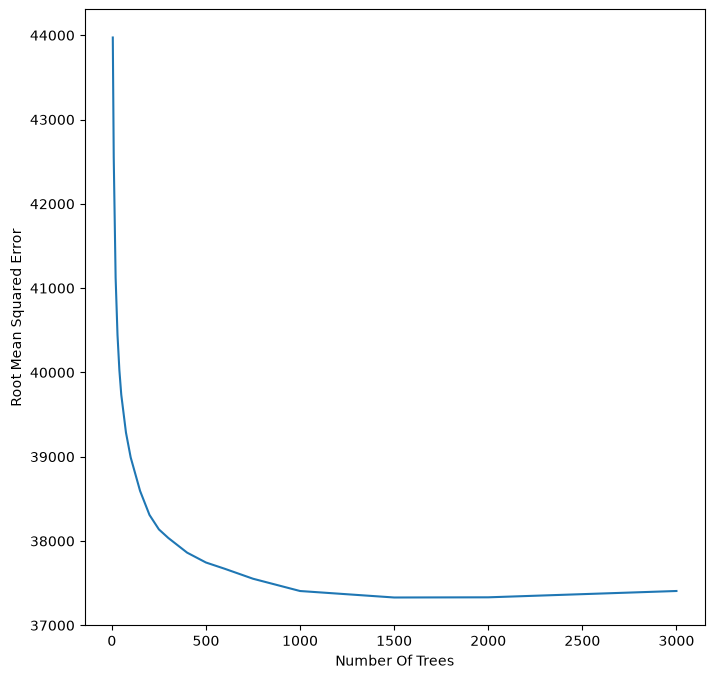

The best number of trees is 1500 which gives a testing root mean squared error of 36058.565 and testing R squared score of 0.402.


,permutation_importance,sse_importance,direction
variables,,,
job_title_short_Data Analyst,2.49,28.17,-26619.926020
job_title_short_Business Analyst,2.49,3.17,-24434.133213
job_title_short_Senior Data Scientist,2.49,3.03,22080.099888
job_title_short_Senior Data Engineer,2.49,1.34,12669.081836
job_title_short_Data Scientist,2.49,1.33,3462.885494
job_title_short_Software Engineer,2.49,1.18,-839.340144
job_title_short_Senior Data Analyst,2.49,0.88,-7930.699974
job_title_short_Machine Learning Engineer,2.49,0.85,17854.019872
job_title_short_Data Engineer,2.49,0.40,-1391.810394


In [3]:
number_of_trees = [5, 10, 20, 30, 40, 50, 75, 100, 150, 200, 250, 300, 400, 500, 600, 750, 1000, 1500, 2000, 3000]
rmses = []
for tree_number in number_of_trees:
    rmses_one_fold = []
    for fold in mlm.kfold_cross_validation(5, len(y_training)):
        inner_model = mlm.Regression_Gradient_Boosting(number_of_trees=tree_number)
        inner_model.fit(np.delete(X_training, fold, axis=0), np.delete(y_training, fold, axis=0))
        predictions = inner_model.predict(X_training[fold])
        rmse = np.sqrt(np.mean((y_training[fold] - predictions)**2))
        rmses_one_fold.append(rmse)
    rmses.append([np.mean(rmses_one_fold), tree_number])
rmses = np.array(rmses)
row_number = np.argmin(rmses[:, 0])
best_tree_number = int(rmses[row_number, 1])

fig, ax = plt.subplots(figsize=(8,8))
ax.plot(rmses[:, 1], rmses[:, 0])
ax.set_xlabel('Number Of Trees')
ax.set_ylabel('Root Mean Squared Error')
plt.show()

model = mlm.Regression_Gradient_Boosting(number_of_trees=best_tree_number)
model.fit(X_training, y_training)
predictions = model.predict(X_testing)
rmse = np.sqrt(np.mean((y_testing - predictions)**2))
r2 = 1 - (np.sum((y_testing - predictions)**2)) / (np.sum((y_testing - np.mean(y_testing))**2))
print(f'The best number of trees is {best_tree_number} which gives a testing root mean squared error of {rmse:.3f} and testing R squared score of {r2:.3f}.')

parameters = predictors
parameters_dictionary = {'variables':parameters, 'permutation_importance':np.round(model.permutation_importances(X_testing, y_testing, groups) * 100, 2), 'sse_importance':np.round(model.feature_importances() * 100, 2), 'direction':model.marginal_importance(X_testing, y_testing, groups, continuous_predictors)}
parameters_df = pd.DataFrame(parameters_dictionary).sort_values(by=['permutation_importance', 'sse_importance'], ascending=False).set_index('variables', drop=True)
display(parameters_df)

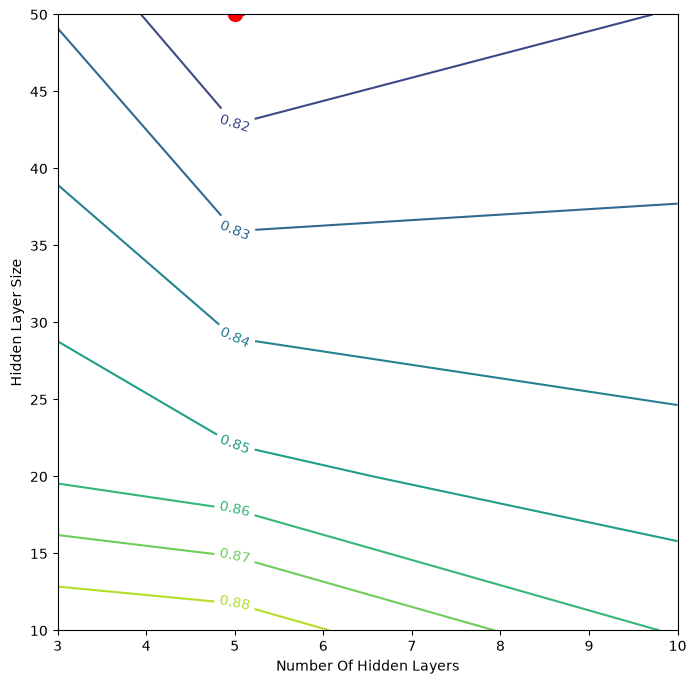

The best number of hidden layers is 5, the best hidden layer size is 50, the best patience is 100, and the best weight decay is 0.1 giving a testing root mean squared error of 37639.071 and a testing R squared score of 0.348.


,permutation_importance,direction
variables,,
job_title_short_Cloud Engineer,5.45,7658.475872
job_title_short_Senior Data Scientist,5.45,51662.399253
job_title_short_Software Engineer,5.45,12982.353408
job_title_short_Data Analyst,5.45,-70605.116650
job_title_short_Data Engineer,5.45,-3881.578534
job_title_short_Data Scientist,5.45,7820.388408
job_title_short_Machine Learning Engineer,5.45,40562.956125
job_title_short_Senior Data Analyst,5.45,-22758.636997
job_title_short_Senior Data Engineer,5.45,32282.088775


In [4]:
hidden_layer_numbers = [3, 5, 10]
hidden_sizes = [10, 20, 50]
patiences = [50, 100, 1000]
weight_decays = [0, 0.01, 0.1]
rmses = np.zeros((len(hidden_layer_numbers), len(hidden_sizes), len(patiences), len(weight_decays)))

for i, hidden_layer_number in enumerate(hidden_layer_numbers):
    for j, hidden_size in enumerate(hidden_sizes):
        for k, patience in enumerate(patiences):
            for l, weight_decay in enumerate(weight_decays):
                rmses_one_fold = []
                for fold in mlm.kfold_cross_validation(5, len(y_training_scaled)):
                    inner_model = mlm.Regression_Neural_Network(hidden_layer_number, hidden_size, epochs=patience, weight_decay=weight_decay)
                    inner_model.fit(np.delete(X_training, fold, axis=0), np.delete(y_training_scaled, fold, axis=0))
                    predictions = inner_model.predict(X_training[fold])
                    rmse = np.sqrt(np.mean((y_training_scaled[fold] - predictions)**2))
                    rmses_one_fold.append(rmse)
                rmses[i, j, k, l] = np.mean(rmses_one_fold)
best_coords = np.argmin(rmses)
best_coords = np.unravel_index(best_coords, rmses.shape)
best_hidden_layer_number = hidden_layer_numbers[best_coords[0]]
best_hidden_size = hidden_sizes[best_coords[1]]
best_patience = patiences[best_coords[2]]
best_weight_decay = weight_decays[best_coords[3]]

fig, ax = plt.subplots(figsize=(8, 8))
plot = ax.contour(hidden_layer_numbers, hidden_sizes, rmses[:, :, best_coords[2], best_coords[3]].T)
ax.set_xlabel('Number Of Hidden Layers')
ax.set_ylabel('Hidden Layer Size')
plt.plot(best_hidden_layer_number, best_hidden_size, marker='o', markersize=10, color='red')
plot.clabel()
plt.show()

model = mlm.Regression_Neural_Network(best_hidden_layer_number, best_hidden_size, epochs=best_patience, weight_decay=best_weight_decay)
model.fit(X_training, y_training_scaled)
predictions = model.predict(X_testing)
predictions_scaled = (predictions * np.std(y_training)) + np.mean(y_training)
rmse = np.sqrt(np.mean((((y_testing_scaled * np.std(y_training)) + np.mean(y_training)) - predictions_scaled)**2))
r2 = 1 - (np.sum((y_testing_scaled - predictions)**2)) / (np.sum((y_testing_scaled - np.mean(y_testing_scaled))**2))
print(f'The best number of hidden layers is {best_hidden_layer_number}, the best hidden layer size is {best_hidden_size}, the best patience is {best_patience}, and the best weight decay is {best_weight_decay} giving a testing root mean squared error of {rmse:.3f} and a testing R squared score of {r2:.3f}.')

parameters = predictors
parameters_dictionary = {'variables':parameters, 'permutation_importance':np.round(model.permutation_importances(X_testing, y_testing, groups) * 100, 2), 'direction':model.marginal_importance(X_testing, y_testing_scaled, groups, continuous_predictors, mean=np.mean(y_training), std=np.mean(y_training))}
parameters_df = pd.DataFrame(parameters_dictionary).sort_values(by='permutation_importance', ascending=False).set_index('variables', drop=True)
display(parameters_df)